<a href="https://colab.research.google.com/github/hmontUSC/movie-recommender-svd/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3: Low-Rank Prediction

## 1. Import your own functions from GitHub

In [1]:
USER, REPO = "hmontUSC", "movie-recommender-svd"
!rm -rf {REPO}
!git clone -q https://github.com/{USER}/{REPO}.git
import sys
sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import baseline

This code downloads a fresh copy of the repository into Colab and imports the split, matrix, RMSE, and baseline functions from its `src` folder.

## 2. The same data, the same split

In [2]:
import os, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv("ml-100k/u.data", sep="\t",
                      names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings)   # seed=0, as in Milestone 2
R = to_matrix(train)
known = ~np.isnan(R)
truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

print("train:", len(train), " test:", len(test))

train: 90032  test: 9968


This code downloads and loads MovieLens 100K, recreates the Milestone 2 train/test split, builds the training matrix `R`, and extracts the test ratings and their matrix positions.

In [3]:
def score(P):
    """Test RMSE of a full 943 x 1682 prediction matrix P."""
    return rmse(np.clip(P[u, i], 1, 5), truth)

This function picks the entries of a full prediction matrix at the hidden test positions, clips them to 1–5 stars, and returns the test RMSE.

## 3. The baseline as a matrix

In [4]:
def baseline_matrix(R):
    """Full matrix of baseline predictions mu + b_user + b_item."""
    mu, b_user, b_item = baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B = baseline_matrix(R)
print("shape:", B.shape)
print("baseline test RMSE:", round(score(B), 4))

shape: (943, 1682)
baseline test RMSE: 0.9545


This code uses broadcasting to turn the user and movie effects into a full matrix of baseline predictions and prints its shape and test RMSE.

In [5]:
def rank_k(U, s, Vt, k):
    """Rank-k matrix from an SVD that was already computed."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This function rebuilds the best rank-k approximation from an already computed SVD by keeping only the first k singular values and vectors.

## 4. Model 1: fill the gaps with each movie's average

In [6]:
mu = np.nanmean(R)
n_item = known.sum(axis=0)
item_mean = np.full(R.shape[1], mu)
has_rating = n_item > 0
item_mean[has_rating] = np.nansum(R, axis=0)[has_rating] / n_item[has_rating]

F = np.where(known, R, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

This code computes each movie's average rating, fills every gap in `R` with it so the matrix has no `nan`, and computes the SVD of the filled matrix.

## 5. Model 2: subtract the baseline first

In [7]:
X = np.where(known, R - B, 0.0)
U2, s2, Vt2 = np.linalg.svd(X, full_matrices=False)

This code subtracts the baseline from each known rating, puts 0 in the gaps, and computes the SVD so it only has to explain the personal part of taste.

## 6. Test error against k

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 400, 943]
err1, err2 = [], []
for k in ks:
    err1.append(score(rank_k(U1, s1, Vt1, k)))
    err2.append(score(rank_k(U2, s2, Vt2, k) + B))
    print(f"k = {k:3d}   model 1: {err1[-1]:.4f}   model 2: {err2[-1]:.4f}")

k =   1   model 1: 1.0060   model 2: 0.9428
k =   2   model 1: 0.9917   model 2: 0.9368
k =   3   model 1: 0.9884   model 2: 0.9356
k =   5   model 1: 0.9790   model 2: 0.9304
k =  10   model 1: 0.9726   model 2: 0.9256
k =  15   model 1: 0.9742   model 2: 0.9250
k =  20   model 1: 0.9745   model 2: 0.9261
k =  30   model 1: 0.9763   model 2: 0.9300
k =  50   model 1: 0.9876   model 2: 0.9363
k = 100   model 1: 1.0048   model 2: 0.9453
k = 200   model 1: 1.0168   model 2: 0.9500
k = 400   model 1: 1.0273   model 2: 0.9543
k = 943   model 1: 1.0284   model 2: 0.9545


This loop computes the test RMSE of Model 1 and Model 2 (adding the baseline `B` back for Model 2) for each rank k and prints the results.

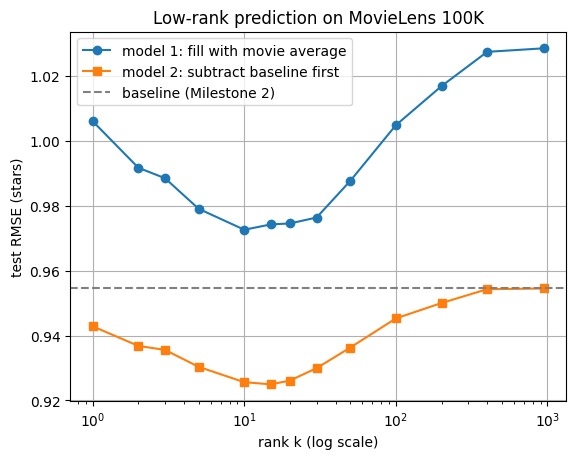

In [9]:
plt.semilogx(ks, err1, "o-", label="model 1: fill with movie average")
plt.semilogx(ks, err2, "s-", label="model 2: subtract baseline first")
plt.axhline(score(B), color="gray", ls="--", label="baseline (Milestone 2)")
plt.xlabel("rank k (log scale)")
plt.ylabel("test RMSE (stars)")
plt.title("Low-rank prediction on MovieLens 100K")
plt.grid(); plt.legend()
plt.savefig("rmse_vs_k.png", dpi=150)
plt.show()

This code plots test RMSE against k for both models with the baseline as a horizontal reference line, and saves the figure as `rmse_vs_k.png`.

## 7. Model 3: refill the gaps and repeat

In [10]:
def iterative_svd_predict(R, k, n_iter=15):
    """Model 2, then repeatedly refill the gaps with the rank-k approximation."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)   # known ratings stay fixed
    return L + B

This function starts from Model 2 and repeatedly refills the gaps with the latest rank-k approximation while keeping the known ratings fixed, then adds the baseline back.

In [11]:
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4],
])
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]
movies = ["Action 1", "Action 2", "Action 3", "Romance 1", "Romance 2", "Romance 3"]

B_toy = baseline_matrix(toy)
P_toy = np.clip(iterative_svd_predict(toy, k=1), 1, 5)

for r, c in np.argwhere(np.isnan(toy)):
    print(f"{users[r]} {movies[c]:10s}  baseline: {B_toy[r, c]:.1f}  model 3: {P_toy[r, c]:.1f}")

Ana Romance 2   baseline: 3.4  model 3: 2.1
Ben Action 2    baseline: 2.1  model 3: 3.2
Cal Action 3    baseline: 3.5  model 3: 5.0
Cal Romance 3   baseline: 3.1  model 3: 1.4
Dee Romance 3   baseline: 2.5  model 3: 4.0
Eve Action 1    baseline: 3.8  model 3: 2.6
Fay Action 3    baseline: 3.2  model 3: 1.4
Fay Romance 2   baseline: 3.0  model 3: 4.5


This code tests Model 3 with k = 1 on the toy matrix from Milestone 1 and prints the baseline and Model 3 predictions for each missing entry.

In [12]:
for k in [2, 5, 10, 20]:
    print(f"k = {k:2d}   model 3: {score(iterative_svd_predict(R, k)):.4f}")

k =  2   model 3: 0.9291
k =  5   model 3: 0.9206
k = 10   model 3: 0.9347
k = 20   model 3: 0.9780


This loop runs iterative SVD imputation on the real training matrix for four values of k and prints the test RMSE for each.